# ML-03 — Embedding + LSTM

Notebook bàn giao được trích từ HuanluyenAi_ML03 (1).ipynb đã chạy ngày 22/10/2026.
Giữ nguyên mã và output của các cell ML-03; không huấn luyện lại khi đóng gói.

## Chạy lại trên Colab

1. Bật GPU (lần chạy được báo cáo sử dụng Tesla T4).
2. Chuẩn bị checkpoint DATA-02 `sic_ai_step10.joblib` tin cậy do nhóm tạo. Checkpoint và mô hình không đi kèm gói Git.
3. Môi trường lần chạy: Python 3.13.15, TensorFlow 2.21.0, Keras 3.13.2, numpy 2.1.3, pandas 2.2.3, scikit-learn 1.6.1. Đọc `docs/ML03_HANDOFF.md` trước khi chạy.
4. Chạy tuần tự các cell bên dưới. Cell đầu yêu cầu upload checkpoint nếu chưa có ở `/content`.
5. Cuối cùng tải ZIP chứa mô hình, cấu hình và kết quả. Điểm lần chạy mới có thể khác do phần cứng và tính không xác định của GPU.

Output giữ lại thuộc run `20261022T152137686036Z`. Không đổi thông số theo điểm test. Tập test đã được xem trước đây; đây là bổ sung bằng chứng trên cùng phép chia, không phải đánh giá độc lập mới.


In [20]:
import joblib
import tensorflow as tf
from pathlib import Path
from google.colab import files

checkpoint_path = Path("/content/sic_ai_step10.joblib")

if not checkpoint_path.exists():
    print("Chọn file sic_ai_step10.joblib vừa tải về:")
    uploaded = files.upload()
    assert checkpoint_path.exists(), (
        "Chưa thấy file /content/sic_ai_step10.joblib"
    )

# Nạp lại đúng bản sao bạn vừa tạo.
saved = joblib.load(checkpoint_path)

train_df = saved["train_df"]
val_df = saved["val_df"]
test_df = saved["test_df"]
traditional_models = saved["traditional_models"]
comparison_df = saved["comparison_df"]
split_manifest = saved["split_manifest"]
validation_predictions = saved["validation_predictions"]
quarantine_review = saved["quarantine_review"]
quarantine_near_conflicts = saved["quarantine_near_conflicts"]

print("Đã khôi phục:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Đã khôi phục:
Train: 30537
Validation: 3824
Test: 3803
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [21]:
import tensorflow as tf
import numpy as np
import pandas as pd

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

MAX_TOKENS = 20000
MAX_LENGTH = 400
BATCH_SIZE = 64

assert tf.config.list_physical_devices("GPU"), "Chưa nhận GPU."

# Chỉ dùng train và validation trong bước này.
train_texts = tf.constant(
    train_df["text_clean"].tolist(), dtype=tf.string
)
val_texts = tf.constant(
    val_df["text_clean"].tolist(), dtype=tf.string
)

y_train_lstm = train_df["label"].to_numpy(dtype=np.float32)
y_val_lstm = val_df["label"].to_numpy(dtype=np.float32)

# Học từ vựng CHỈ từ train.
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    name="text_vectorizer",
)

vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(train_texts).batch(256)
)

train_ds = (
    tf.data.Dataset.from_tensor_slices((train_texts, y_train_lstm))
    .shuffle(len(train_df), seed=42, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Không shuffle validation để giữ đúng thứ tự khi đối chiếu dự đoán.
val_ds = (
    tf.data.Dataset.from_tensor_slices((val_texts, y_val_lstm))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Đưa bộ chuyển văn bản vào mô hình để lưu cùng từ vựng.
inputs = tf.keras.Input(shape=(), dtype=tf.string, name="text_clean")
x = vectorizer(inputs)
x = tf.keras.layers.Embedding(
    input_dim=vectorizer.vocabulary_size(),
    output_dim=128,
    mask_zero=True,
)(x)
x = tf.keras.layers.LSTM(64)(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(32, activation="relu")(x)
outputs = tf.keras.layers.Dense(
    1, activation="sigmoid", name="score_real"
)(x)

lstm_model = tf.keras.Model(inputs, outputs)

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001, clipnorm=1.0
    ),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy")],
    jit_compile=False,
)

print("Số mục từ vựng:", vectorizer.vocabulary_size())
lstm_model.summary()

Số mục từ vựng: 20000


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_clean          │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorizer     │ (None, 400)       │          0 │ text_clean[0][0]  │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 400, 128)  │  2,560,000 │ text_vectorizer[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 400)       │          0 │ text_vectorizer[… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     49,408 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ score_real (Dense)  │ (None, 1)         │         33 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,611,521 (9.96 MB)

 Trainable params: 2,611,521 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# ML-03 — HUẤN LUYỆN, DỪNG SỚM VÀ NẠP CHECKPOINT TỐT NHẤT
# Chạy sau cell tạo lstm_model, train_ds và val_ds.
import json
import hashlib
import platform
import time
from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version
from itertools import combinations
from sklearn.metrics import accuracy_score, f1_score

# Không chia lại dữ liệu; dùng các tập đã khôi phục từ checkpoint DATA-02.
parts = {'train': train_df, 'validation': val_df, 'test': test_df}
for name, part in parts.items():
    assert part['_row_id'].is_unique, f'Trùng ID trong {name}'
    assert set(part['label'].unique()) == {0, 1}
for (name_a, a), (name_b, b) in combinations(parts.items(), 2):
    for key in ['_row_id', 'group_id']:
        assert not set(a[key]) & set(b[key]), f'Trùng {key}: {name_a}/{name_b}'
current_manifest = pd.concat([
    part[['_row_id', 'group_id', 'label']].assign(split=name)
    for name, part in parts.items()
], ignore_index=True).sort_values('_row_id').reset_index(drop=True)
expected_manifest = split_manifest[current_manifest.columns].sort_values('_row_id').reset_index(drop=True)
pd.testing.assert_frame_equal(current_manifest, expected_manifest, check_dtype=False)

# Thư mục riêng từng lần chạy, tránh vô tình nạp checkpoint của lần trước.
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
lstm_run_dir = Path('/content') / ('sic_ai_ml03_' + run_id)
lstm_run_dir.mkdir(parents=True, exist_ok=False)
current_manifest.to_csv(lstm_run_dir / 'split_manifest.csv', index=False)
best_path = lstm_run_dir / 'best_lstm.keras'

MAX_EPOCHS = 15
PATIENCE = 2
callbacks = [
    tf.keras.callbacks.TerminateOnNaN(),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_path), monitor='val_loss', mode='min', save_best_only=True,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', mode='min', patience=PATIENCE,
        min_delta=0.0, restore_best_weights=True, verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(str(lstm_run_dir / 'training_log.csv')),
]
started = time.perf_counter()
lstm_history = lstm_model.fit(
    train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
    callbacks=callbacks, verbose=1,
)
training_seconds = time.perf_counter() - started
assert best_path.is_file(), 'Không tạo được checkpoint LSTM.'
assert np.isfinite(lstm_history.history['val_loss']).all(), 'val_loss không hữu hạn.'

# Luôn nạp mô hình tốt nhất theo validation trước khi đánh giá.
# Từ vựng TextVectorization được lưu cùng trong file .keras.
lstm_model = tf.keras.models.load_model(str(best_path), compile=False)
val_scores = lstm_model.predict(val_ds, verbose=0).ravel()
assert len(val_scores) == len(val_df) and np.isfinite(val_scores).all()
lstm_val_pred = (val_scores >= 0.5).astype(int)
lstm_row = {
    'mô hình': 'LSTM',
    'Accuracy': accuracy_score(y_val_lstm, lstm_val_pred),
    'F1-macro': f1_score(y_val_lstm, lstm_val_pred, average='macro', zero_division=0),
    'F1-Fake (nhãn 0)': f1_score(y_val_lstm, lstm_val_pred, pos_label=0, zero_division=0),
}
comparison_df = pd.concat([
    comparison_df.loc[comparison_df['mô hình'].ne('LSTM')], pd.DataFrame([lstm_row])
], ignore_index=True).sort_values('F1-macro', ascending=False).reset_index(drop=True)
comparison_df.to_csv(lstm_run_dir / 'validation_comparison.csv', index=False)
validation_predictions['LSTM'] = lstm_val_pred
val_export = val_df[['_row_id', 'group_id', 'label']].copy()
val_export['score_real'] = val_scores
val_export['prediction'] = lstm_val_pred
val_export.to_csv(lstm_run_dir / 'validation_predictions.csv', index=False)

run_metadata = {
    'run_id': run_id, 'seed': 42, 'labels': {'Fake': 0, 'Real': 1},
    'input': 'text_clean; áp dụng clean_source_markers trước khi suy luận văn bản gốc',
    'vocabulary_fit': 'train_only', 'max_tokens': MAX_TOKENS,
    'sequence_length': MAX_LENGTH, 'batch_size': BATCH_SIZE,
    'max_epochs': MAX_EPOCHS, 'epochs_completed': len(lstm_history.history['loss']),
    'early_stopping': {'monitor': 'val_loss', 'mode': 'min', 'patience': PATIENCE,
                       'restore_best_weights': True},
    'best_epoch_1_based': int(np.argmin(lstm_history.history['val_loss'])) + 1,
    'training_seconds': training_seconds, 'threshold_real': 0.5,
    'split_manifest_sha256': hashlib.sha256((lstm_run_dir / 'split_manifest.csv').read_bytes()).hexdigest(),
    'checkpoint_sha256': hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
    'model_sha256': hashlib.sha256(best_path.read_bytes()).hexdigest(),
    'versions': {name: version(name) for name in ['tensorflow', 'keras', 'numpy', 'pandas', 'scikit-learn']},
    'python': platform.python_version(), 'platform': platform.platform(),
    'devices': [{'name': d.name, 'type': d.device_type,
                 'details': {k: str(v) for k, v in tf.config.experimental.get_device_details(d).items()}}
                for d in tf.config.list_physical_devices()],
    'note': 'Lần huấn luyện mới; không gán kết quả cũ cho mô hình mới. Không chọn tham số bằng test.',
}
(lstm_run_dir / 'run_metadata.json').write_text(
    json.dumps(run_metadata, ensure_ascii=False, indent=2), encoding='utf-8'
)
display(comparison_df.round(4))
print('Epoch tốt nhất:', run_metadata['best_epoch_1_based'])
print('Đã nạp:', best_path)

Epoch 1/15
478/478 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.9392 - loss: 0.1640 - val_accuracy: 0.9825 - val_loss: 0.0699
Epoch 2/15
478/478 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step - accuracy: 0.9847 - loss: 0.0600 - val_accuracy: 0.9712 - val_loss: 0.1032
Epoch 3/15
478/478 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.9896 - loss: 0.0404 - val_accuracy: 0.9822 - val_loss: 0.0718
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


,mô hình,Accuracy,F1-macro,F1-Fake (nhãn 0)
0,TF-IDF + Linear SVM,0.9922,0.9921,0.9911
1,TF-IDF + Logistic Regression,0.9848,0.9846,0.9828
2,LSTM,0.9825,0.9822,0.9802
3,TF-IDF + Multinomial Naive Bayes,0.9563,0.9558,0.9508
4,Luôn đoán lớp phổ biến,0.5560,0.3573,0.0000


Epoch tốt nhất: 1
Đã nạp: /content/sic_ai_ml03_20261022T152137686036Z/best_lstm.keras


In [23]:
# ML-03 — ĐO THỜI GIAN SUY LUẬN TRÊN CÙNG MẪU VALIDATION
# Đo predict(text_clean), gồm vectorization; không gồm tải model, đọc file,
# làm sạch nguồn, mạng hoặc giao diện. Không dùng thời gian này để chọn theo test.
import time
import json
import numpy as np
import pandas as pd

benchmark_texts = val_df['text_clean'].head(256).tolist()
assert benchmark_texts
repeats = 5
timing_rows = []

def lstm_predict_texts(texts):
    # .numpy() chờ thiết bị tính xong, tránh chỉ đo thời gian lên lịch GPU.
    return lstm_model(tf.constant(texts, dtype=tf.string), training=False).numpy()

predictors = dict(traditional_models)
predict_functions = {name: model.predict for name, model in predictors.items()}
predict_functions['LSTM'] = lstm_predict_texts
for name, predict_fn in predict_functions.items():
    for batch_size in [1, 64]:
        texts = benchmark_texts[:batch_size]
        for _ in range(2):
            predict_fn(texts)  # warm-up; không đưa vào thống kê
        samples_ms = []
        for repeat in range(repeats):
            start = time.perf_counter()
            result = predict_fn(texts)
            duration_ms = (time.perf_counter() - start) * 1000
            assert len(result) == len(texts)
            samples_ms.append(duration_ms)
            timing_rows.append({'model': name, 'batch_size': len(texts),
                                'repeat': repeat + 1, 'elapsed_ms': duration_ms})
        print(name, 'batch', len(texts), 'median ms:', round(float(np.median(samples_ms)), 3))

timing_samples = pd.DataFrame(timing_rows)
timing_samples.to_csv(lstm_run_dir / 'inference_timing_samples.csv', index=False)
timing_summary = timing_samples.groupby(['model', 'batch_size'])['elapsed_ms'].agg(
    median_ms='median', min_ms='min', max_ms='max'
).reset_index()
timing_summary['amortized_ms_per_article'] = timing_summary['median_ms'] / timing_summary['batch_size']
timing_summary.to_csv(lstm_run_dir / 'inference_timing_summary.csv', index=False)
run_metadata['benchmark'] = {
    'source': 'validation, first rows in saved order', 'warmup_calls': 2,
    'repeats': repeats, 'batch_sizes': [1, 64],
    'scope': 'text_clean -> vectorization -> prediction; model already loaded',
    'note': 'Batch 64 ms/article là chi phí trung bình theo lô, không phải độ trễ một yêu cầu. '
            'SVM dùng CPU; LSTM có thể dùng GPU. Chỉ so sánh với thông tin thiết bị kèm theo.',
}
(lstm_run_dir / 'run_metadata.json').write_text(
    json.dumps(run_metadata, ensure_ascii=False, indent=2), encoding='utf-8'
)
display(timing_summary)

TF-IDF + Logistic Regression batch 1 median ms: 1.545
TF-IDF + Logistic Regression batch 64 median ms: 36.754
TF-IDF + Linear SVM batch 1 median ms: 1.485
TF-IDF + Linear SVM batch 64 median ms: 36.917
TF-IDF + Multinomial Naive Bayes batch 1 median ms: 1.902
TF-IDF + Multinomial Naive Bayes batch 64 median ms: 34.679
LSTM batch 1 median ms: 27.853
LSTM batch 64 median ms: 36.206


,model,batch_size,median_ms,min_ms,max_ms,amortized_ms_per_article
0,LSTM,1,27.853015,27.722536,35.340644,27.853015
1,LSTM,64,36.206446,35.499935,38.042942,0.565726
2,TF-IDF + Linear SVM,1,1.484785,1.380661,1.524495,1.484785
3,TF-IDF + Linear SVM,64,36.917481,34.409128,50.367972,0.576836
4,TF-IDF + Logistic Regression,1,1.545120,1.373768,2.255166,1.545120
5,TF-IDF + Logistic Regression,64,36.753691,34.620380,38.194643,0.574276
6,TF-IDF + Multinomial Naive Bayes,1,1.902028,1.715423,2.095755,1.902028
7,TF-IDF + Multinomial Naive Bayes,64,34.678673,33.769152,35.685541,0.541854


Mô hình được chọn theo validation: TF-IDF + Linear SVM
Đang đánh giá: TF-IDF + Logistic Regression
Đang đánh giá: TF-IDF + Linear SVM
Đang đánh giá: TF-IDF + Multinomial Naive Bayes
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step

KẾT QUẢ TEST:


,mô hình,Accuracy,F1-macro,F1-Fake (nhãn 0),số bài sai,đã chọn theo validation
0,TF-IDF + Logistic Regression,0.9829,0.9827,0.9807,65,False
1,TF-IDF + Linear SVM,0.9932,0.9931,0.9923,26,True
2,TF-IDF + Multinomial Naive Bayes,0.9514,0.9508,0.9453,185,False
3,LSTM,0.9774,0.9771,0.9745,86,False



LINEAR SVM — TEST:
              precision    recall  f1-score   support

    Fake (0)     0.9923    0.9923    0.9923      1692
    Real (1)     0.9938    0.9938    0.9938      2111

    accuracy                         0.9932      3803
   macro avg     0.9931    0.9931    0.9931      3803
weighted avg     0.9932    0.9932    0.9932      3803



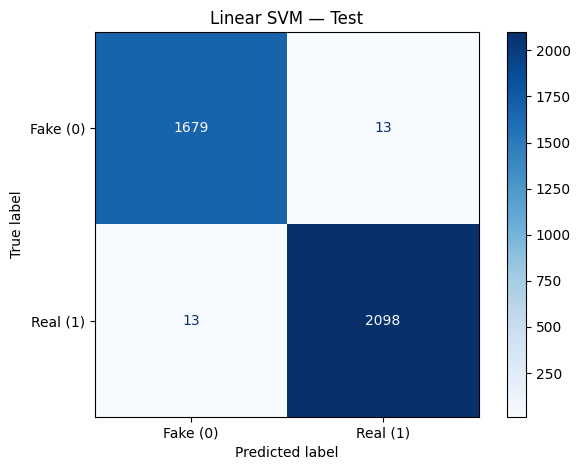

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Chốt từ kết quả VALIDATION, trước khi xem điểm test.
selected_model_name = "TF-IDF + Linear SVM"
print("Mô hình được chọn theo validation:", selected_model_name)

X_test = test_df["text_clean"]
y_test = test_df["label"].to_numpy(dtype=int)

# 1. Dự đoán bằng các mô hình truyền thống đã huấn luyện.
test_predictions = {}

for name, trained_pipeline in traditional_models.items():
    print("Đang đánh giá:", name)
    test_predictions[name] = trained_pipeline.predict(X_test)

# 2. LSTM tốt nhất theo val_loss đã được nạp ở bước 11.
test_text_ds = (
    tf.data.Dataset.from_tensor_slices(
        tf.constant(X_test.tolist(), dtype=tf.string)
    )
    .batch(64)
)

lstm_test_scores = lstm_model.predict(
    test_text_ds, verbose=1
).ravel()

assert np.isfinite(lstm_test_scores).all()
test_predictions["LSTM"] = (
    lstm_test_scores >= 0.5
).astype(int)

# 3. Bảng kết quả test của các cấu hình đã chốt.
rows = []

for name, predictions in test_predictions.items():
    assert len(predictions) == len(y_test)

    rows.append({
        "mô hình": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1-macro": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "F1-Fake (nhãn 0)": f1_score(
            y_test, predictions,
            pos_label=0, zero_division=0
        ),
        "số bài sai": int(np.sum(predictions != y_test)),
        "đã chọn theo validation": name == selected_model_name,
    })

test_results_df = pd.DataFrame(rows)

print("\nKẾT QUẢ TEST:")
display(test_results_df.round(4))

# 4. Xem chi tiết mô hình đã chọn.
selected_test_pred = test_predictions[selected_model_name]

print("\nLINEAR SVM — TEST:")
print(classification_report(
    y_test,
    selected_test_pred,
    labels=[0, 1],
    target_names=["Fake (0)", "Real (1)"],
    digits=4,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    selected_test_pred,
    labels=[0, 1],
    display_labels=["Fake (0)", "Real (1)"],
    cmap="Blues",
    values_format="d",
)
plt.title("Linear SVM — Test")
plt.tight_layout()

# 5. Lưu kết quả và dự đoán để đối chiếu sau.
result_dir = Path("/content/sic_ai_test_results")
result_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    result_dir / "svm_test_confusion_matrix.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

test_results_df.to_csv(
    result_dir / "test_metrics.csv", index=False
)

prediction_table = test_df[
    ["_row_id", "group_id", "label"]
].copy()

for name, predictions in test_predictions.items():
    prediction_table[name] = predictions

prediction_table.to_csv(
    result_dir / "test_predictions.csv", index=False
)

import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/sic_ai_step12_test", "zip", root_dir=result_dir
)
files.download(archive)

In [25]:
# ML-03 — LƯU ĐÁNH GIÁ TEST CỦA LẦN CHẠY MỚI VÀ TẢI GÓI KẾT QUẢ
# Chạy sau cell đánh giá test. Không thay tham số vì điểm test.
import shutil
from google.colab import files

test_results_df.to_csv(lstm_run_dir / 'test_metrics.csv', index=False)
prediction_table.to_csv(lstm_run_dir / 'test_predictions.csv', index=False)
archive = shutil.make_archive(str(lstm_run_dir), 'zip', root_dir=lstm_run_dir)
print('Gói kết quả ML-03:', archive)
files.download(archive)

Gói kết quả ML-03: /content/sic_ai_ml03_20261022T152137686036Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Kết luận ML-03

Mô hình sử dụng TextVectorization → Embedding → LSTM → Dense. Từ vựng chỉ học trên tập train; chuỗi đầu vào có độ dài 400.

Huấn luyện dừng sớm sau 3 epoch. Mô hình tại epoch 1 được chọn vì có validation loss thấp nhất.

Trên cùng tập test gồm 3.803 bài:
- LSTM: Accuracy 97,74%, F1-macro 97,71%, sai 86 bài.
- SVM: Accuracy 99,32%, F1-macro 99,31%, sai 26 bài.

SVM đạt kết quả cao hơn trong thí nghiệm này và tiếp tục là mô hình triển khai đã chọn từ validation.

Thời gian suy luận LSTM trên một bài mẫu là 27,85 ms, lấy trung vị 5 lần đo sau warm-up. Phép đo gồm vectorization và dự đoán, không gồm tải mô hình, làm sạch nguồn, mạng hoặc giao diện. Môi trường có GPU Tesla T4; SVM dùng CPU. Đây chưa phải phép đo tốc độ toàn hệ thống.

Tập test đã được xem trong thí nghiệm trước. Lần chạy này bổ sung bằng chứng tái lập, không dùng kết quả test để điều chỉnh tham số.